# 05 · Selección de variables y PCA

**Jorge Javier Palma Martínez · ML1 FIUNA · 2026**

Protocolo: `rectangular-masked-v3-2026-11-22`.

Se prueban doce representaciones adicionales. ANOVA usa las etiquetas y PCA conserva variación; ninguno se fuerza en el modelo final.

Este cuaderno contiene el código ejecutable de la etapa, dividido en celdas con explicación. Ejecutar de arriba hacia abajo. Los notebooks se recorren del 01 al 06; los ajustes y las curvas pueden tardar varios minutos.

## 1. Librerías y ubicación del proyecto

Se cargan las bibliotecas utilizadas y se localiza la carpeta raíz. La misma celda funciona al abrir el notebook desde la raíz o desde `notebooks`. No entrena ningún modelo.

In [1]:
from pathlib import Path
import sys, json, hashlib, shutil, time, warnings, copy
import numpy as np
import pandas as pd
import cv2
import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/workflow.py").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    cohen_kappa_score,
)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.base import clone
from xgboost import XGBClassifier
from src.features import FEATURE_COUNT, PREPROCESSING_SPEC
from src.models import SVDSubspaceClassifier


## 2. Configuración y carpetas de salida

Se fija la semilla, el orden de las cinco etiquetas y las rutas de matrices, informes y modelos. Crear estas carpetas no modifica las radiografías originales.

In [2]:
DATA = ROOT / "data/processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
MODELS = ROOT / "models"
LABELS = ["Normal", "Dudosa", "Leve", "Moderada", "Severa"]
SEED = 42
PROTOCOL = "rectangular-masked-v3-2026-11-22"
for folder in [DATA, REPORTS, FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
print("Proyecto:", ROOT)
print("Protocolo:", PROTOCOL)


Proyecto: c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\repositorio-entrega\TP_4\proyecto-rodilla
Protocolo: rectangular-masked-v3-2026-11-22


## 3. Guardar resultados y mostrar las figuras

La primera función exporta JSON evitando NaN/Infinity. La segunda guarda cada gráfico y lo muestra dentro del notebook, para que el documento conserve código y salida al verse en GitHub.

In [3]:
def save_json(path, value):
    def finite(item):
        if isinstance(item, dict):
            return {k: finite(v) for k, v in item.items()}
        if isinstance(item, (list, tuple)):
            return [finite(v) for v in item]
        if isinstance(item, np.generic):
            item = item.item()
        if isinstance(item, float) and not np.isfinite(item):
            return None
        return item

    Path(path).write_text(
        json.dumps(
            finite(value), ensure_ascii=False, indent=2, allow_nan=False, default=str
        ),
        encoding="utf-8",
    )


def figure(name):
    path = FIGURES / name
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.close()
    display(Image(filename=str(path)))


## 4. Leer las matrices y definir las métricas

El cargador rechaza matrices de otra versión. La función de evaluación calcula accuracy, balanced accuracy, F1 y precisión/recall macro. F1 macro es el criterio de selección; no se ajustan transformaciones con test.

In [4]:
def arrays():
    payload = np.load(DATA / "features_arrays.npz")
    if "protocol" not in payload or str(payload["protocol"]) != PROTOCOL:
        raise ValueError(
            "Matrices de otra versión; ejecutar antes el preprocesamiento."
        )
    return payload


def score(y, pred):
    return {
        "Accuracy (%)": round(accuracy_score(y, pred) * 100, 4),
        "Balanced Acc (%)": round(balanced_accuracy_score(y, pred) * 100, 4),
        "F1 Macro": round(f1_score(y, pred, average="macro", zero_division=0), 6),
        "F1 Weighted": round(f1_score(y, pred, average="weighted", zero_division=0), 6),
        "Precision Macro": round(
            precision_score(y, pred, average="macro", zero_division=0), 6
        ),
        "Recall Macro": round(
            recall_score(y, pred, average="macro", zero_division=0), 6
        ),
    }


a = arrays()
display({k: v.shape for k, v in a.items() if k.startswith("X_")})


{'X_train_tabular': (1103, 288),
 'X_train_flat': (1103, 2304),
 'X_val_tabular': (236, 288),
 'X_val_flat': (236, 2304),
 'X_test_tabular': (237, 288),
 'X_test_flat': (237, 2304)}

## 5. Bucle completo de entrenamiento y validación

Este es el código que recorre candidatos: toma train, ejecuta `fit`, predice validación, calcula métricas y guarda modelos y resultados. El escalador/selector de cada Pipeline se ajusta solo con train. La función no accede a las entradas de test.

In [5]:
def fit_candidates(specs, filename):
    a = arrays()
    rows = []
    fitted = {}
    for name, family, kind, model in specs:
        X = a[f"X_train_{kind}"]
        V = a[f"X_val_{kind}"]
        t = time.perf_counter()
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", category=FutureWarning)
            model.fit(X, a["y_train"])
        metrics = score(a["y_val"], model.predict(V))
        rows.append(
            dict(
                Modelo=name,
                family=family,
                input_kind=kind,
                **metrics,
                seconds=round(time.perf_counter() - t, 2),
            )
        )
        fitted[name] = model
        print(name, metrics["F1 Macro"], flush=True)
    table = pd.DataFrame(rows).sort_values("F1 Macro", ascending=False, kind="stable")
    save_json(REPORTS / filename, table.to_dict(orient="records"))
    joblib.dump(fitted, MODELS / (filename.replace(".json", "_candidates.joblib")))
    return table


## 6. Estimadores base para comparar representaciones

Se mantienen los mismos parámetros de SVM y XGBoost que en el notebook anterior para que los candidatos tengan una definición reproducible.

In [6]:
def svc(C=10):
    return SVC(
        C=C, kernel="rbf", class_weight="balanced", probability=True, random_state=SEED
    )


def xgb(n=200):
    return XGBClassifier(
        n_estimators=n,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        random_state=SEED,
        n_jobs=2,
    )


## 7. Pipelines con selección ANOVA

SelectKBest conserva 40,80,160 variables según el estadístico F. El selector se ajusta dentro del Pipeline con train; SVM agrega escalado y compara C=10/50.

In [7]:
specs = []

for k in [40, 80, 160]:
    for C in [10.0, 50.0]:
        specs.append(
            (
                f"SVM ANOVA{k} C={C:g}",
                "SVM",
                "tabular",
                Pipeline(
                    [
                        ("select", SelectKBest(f_classif, k=k)),
                        ("scale", StandardScaler()),
                        ("clf", svc(C)),
                    ]
                ),
            )
        )
    specs.append(
        (
            f"XGBoost ANOVA{k}",
            "XGBoost",
            "tabular",
            Pipeline([("select", SelectKBest(f_classif, k=k)), ("clf", xgb(200))]),
        )
    )


## 8. Pipelines con PCA

Se estandariza antes de PCA y se comparan 32,64,128 componentes con SVM C=10. PCA no utiliza etiquetas y varianza retenida no equivale necesariamente a poder predictivo.

In [8]:
for n in [32, 64, 128]:
    specs.append(
        (
            f"SVM PCA{n} C=10",
            "SVM",
            "tabular",
            Pipeline(
                [
                    ("scale", StandardScaler()),
                    ("pca", PCA(n_components=n, random_state=SEED)),
                    ("clf", svc(10)),
                ]
            ),
        )
    )


## 9. Ajustar y evaluar representaciones

Se entrena cada Pipeline con train y se mide en validación. No se utiliza test para elegir k ni la cantidad de componentes.

In [9]:
table = fit_candidates(specs, "feature_validation.json")
display(table)


SVM ANOVA40 C=10 0.53203
SVM ANOVA40 C=50 0.511364
XGBoost ANOVA40 0.504869
SVM ANOVA80 C=10 0.589296
SVM ANOVA80 C=50 0.625267
XGBoost ANOVA80 0.558527
SVM ANOVA160 C=10 0.603059
SVM ANOVA160 C=50 0.599237
XGBoost ANOVA160 0.580117
SVM PCA32 C=10 0.611749
SVM PCA64 C=10 0.618292
SVM PCA128 C=10 0.600281


,Modelo,family,input_kind,Accuracy (%),Balanced Acc (%),F1 Macro,F1 Weighted,Precision Macro,Recall Macro,seconds
4,SVM ANOVA80 C=50,SVM,tabular,64.4068,61.7266,0.625267,0.640430,0.641478,0.617266,0.43
10,SVM PCA64 C=10,SVM,tabular,62.2881,61.1112,0.618292,0.620492,0.632931,0.611112,0.41
9,SVM PCA32 C=10,SVM,tabular,60.5932,60.5309,0.611749,0.607783,0.619843,0.605309,0.36
6,SVM ANOVA160 C=10,SVM,tabular,61.8644,60.5052,0.603059,0.614070,0.610505,0.605052,0.54
11,SVM PCA128 C=10,SVM,tabular,61.8644,59.4619,0.600281,0.614634,0.612380,0.594619,0.49
7,SVM ANOVA160 C=50,SVM,tabular,61.8644,60.1808,0.599237,0.613108,0.607339,0.601808,0.48
3,SVM ANOVA80 C=10,SVM,tabular,61.4407,58.7265,0.589296,0.609108,0.597945,0.587265,0.40
8,XGBoost ANOVA160,XGBoost,tabular,62.2881,57.6490,0.580117,0.609225,0.607125,0.576490,5.03
5,XGBoost ANOVA80,XGBoost,tabular,59.3220,55.6571,0.558527,0.581407,0.579405,0.556571,2.39
0,SVM ANOVA40 C=10,SVM,tabular,55.9322,53.2702,0.532030,0.554917,0.542620,0.532702,0.59


## 10. Comparar con las entradas completas

Se agregan los SVM y XGBoost sin reducción del notebook 04. Esto permite comprobar si seleccionar o proyectar supera a conservar las 288 variables.

,Modelo,F1 Macro,Accuracy (%)
12,SVM RBF C=1,0.629974,64.4068
0,SVM ANOVA80 C=50,0.625267,64.4068
1,SVM PCA64 C=10,0.618292,62.2881
13,XGBoost 200 rondas,0.617142,64.4068
14,XGBoost 300 rondas,0.616885,64.8305
15,SVM RBF C=50,0.613015,63.1356
2,SVM PCA32 C=10,0.611749,60.5932
16,SVM RBF C=10,0.611277,63.1356
3,SVM ANOVA160 C=10,0.603059,61.8644
4,SVM PCA128 C=10,0.600281,61.8644


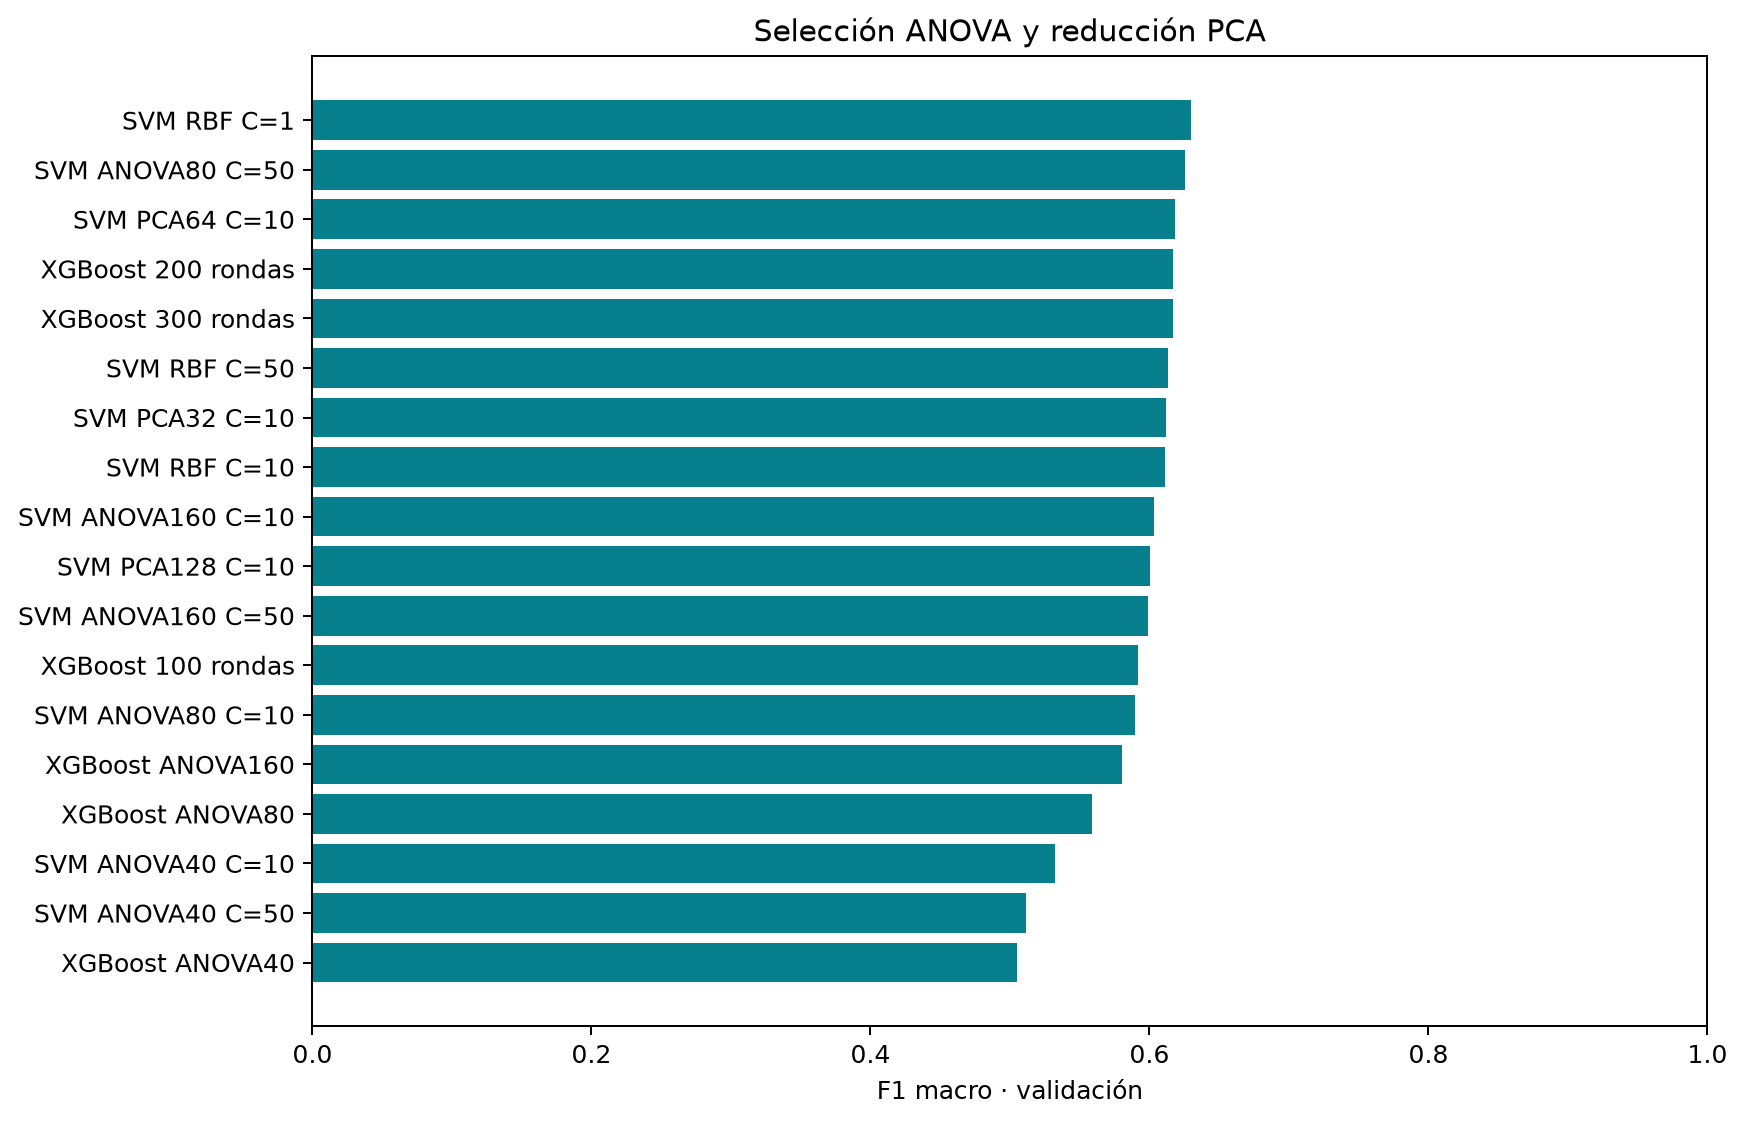

In [10]:
advanced = pd.DataFrame(
    json.loads((REPORTS / "advanced_validation.json").read_text(encoding="utf-8"))
)
comparison = pd.concat(
    [table, advanced[advanced.family.isin(["SVM", "XGBoost"])]], ignore_index=True
).sort_values("F1 Macro", ascending=False)
display(comparison[["Modelo", "F1 Macro", "Accuracy (%)"]])
plt.figure(figsize=(10, 7))
plt.barh(comparison.Modelo[::-1], comparison["F1 Macro"][::-1], color="#087f8c")
plt.xlim(0, 1)
plt.xlabel("F1 macro · validación")
plt.title("Selección ANOVA y reducción PCA")
figure("feature_engineering_validation.png")


## Interpretación

En la revisión vigente ganó SVM RBF C=1 con las 288 variables. ANOVA y PCA se implementaron y evaluaron; no se eligieron por el criterio de validación.